## 1. Carga de los datos

Importo pandas y cargo el archivo de perfiles en `df_demo`.

Aunque el archivo tiene extensión `.txt`, sus datos están separados por comas, por lo que puedo leerlo con `pd.read_csv()`.

Muestro las primeras cinco filas con `.head()` para comprobar la carga y reconocer las columnas.

In [3]:
import pandas as pd

In [4]:
df_demo = pd.read_csv("data/df_final_demo.txt")

df_demo.head()

,client_id,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
0,836976,6.0,73.0,60.5,U,2.0,45105.30,6.0,9.0
1,2304905,7.0,94.0,58.0,U,2.0,110860.30,6.0,9.0
2,1439522,5.0,64.0,32.0,U,2.0,52467.79,6.0,9.0
3,1562045,16.0,198.0,49.0,M,2.0,67454.65,3.0,6.0
4,5126305,12.0,145.0,33.0,F,2.0,103671.75,0.0,3.0


## 2. Estructura y datos disponibles

Utilizo `.info()` para comprobar el número de filas y columnas, los tipos de datos y cuántos valores no nulos hay en cada columna.

In [5]:
df_demo.info()

<class 'pandas.DataFrame'>
RangeIndex: 70609 entries, 0 to 70608
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   client_id         70609 non-null  int64  
 1   clnt_tenure_yr    70595 non-null  float64
 2   clnt_tenure_mnth  70595 non-null  float64
 3   clnt_age          70594 non-null  float64
 4   gendr             70595 non-null  str    
 5   num_accts         70595 non-null  float64
 6   bal               70595 non-null  float64
 7   calls_6_mnth      70595 non-null  float64
 8   logons_6_mnth     70595 non-null  float64
dtypes: float64(7), int64(1), str(1)
memory usage: 4.9 MB


El archivo contiene **70.609 filas y 9 columnas**.

- `client_id` no tiene valores nulos.
- `clnt_age` tiene 15 valores nulos.
- Las otras siete columnas tienen 14 valores nulos cada una.

A continuación reviso las filas afectadas para comprobar si los datos ausentes corresponden a los mismos clientes.

## 3. Revisión de valores nulos

Selecciono las filas que tienen al menos un dato ausente.

`.isna()` identifica los nulos y `.any(axis=1)` comprueba si hay alguno en cada fila.

In [6]:
df_demo[df_demo.isna().any(axis=1)]

,client_id,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
4164,7402828,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8316,355337,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8677,8412164,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9583,4666211,8.0,106.0,NaN,F,2.0,42550.55,4.0,7.0
13444,2222915,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
18066,4876926,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25961,5277910,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28432,7616759,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
35323,8191345,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
43518,1227228,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


He encontrado **15 clientes con algún dato ausente**:

- 14 solo tienen el identificador `client_id`; el resto de su perfil está vacío.
- El cliente `4666211` únicamente tiene la edad vacía.

**Decisión provisional:** conservar estos registros y no rellenar los datos ausentes. Aunque les falte información de perfil, podrían tener actividad web y una asignación al experimento.

En los análisis de edad, saldo u otras características, tendré en cuenta cuántos clientes tienen información disponible.

## 4. Comprobación de clientes duplicados

Compruebo si algún `client_id` aparece más de una vez, ya que este archivo debería contener una única fila por cliente.

In [7]:
df_demo['client_id'].duplicated().sum()

np.int64(0)

No hay identificadores duplicados. Como tampoco hay identificadores nulos, el archivo contiene **70.609 clientes únicos**, con una fila por cliente.

## 5. Resumen de las variables numéricas

Utilizo `.describe()` para revisar medias, medianas, cuartiles y valores mínimos y máximos.

Esta primera revisión ayuda a conocer los datos y a detectar valores que debamos investigar. Los cálculos excluyen los valores nulos de cada columna.

Aunque aparece en el resumen, no interpreto las estadísticas de `client_id`, porque es un identificador.

In [8]:
df_demo.describe()

,client_id,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,num_accts,bal,calls_6_mnth,logons_6_mnth
count,7.060900e+04,70595.000000,70595.000000,70594.000000,70595.000000,7.059500e+04,70595.000000,70595.000000
mean,5.004992e+06,12.052950,150.659367,46.442240,2.255528,1.474452e+05,3.382478,5.566740
std,2.877278e+06,6.871819,82.089854,15.591273,0.534997,3.015087e+05,2.236580,2.353286
min,1.690000e+02,2.000000,33.000000,13.500000,1.000000,1.378942e+04,0.000000,1.000000
25%,2.519329e+06,6.000000,82.000000,32.500000,2.000000,3.734683e+04,1.000000,4.000000
50%,5.016978e+06,11.000000,136.000000,47.000000,2.000000,6.333290e+04,3.000000,5.000000
75%,7.483085e+06,16.000000,192.000000,59.000000,2.000000,1.375449e+05,6.000000,7.000000
max,9.999839e+06,62.000000,749.000000,96.000000,8.000000,1.632004e+07,7.000000,9.000000


## 6. Revisión de la variable de género

Compruebo qué códigos aparecen en `gendr` y cuántos clientes hay en cada uno, incluyendo los valores nulos.

Antes de cambiar sus etiquetas, revisaré su significado para no interpretar incorrectamente los códigos.

In [9]:
df_demo['gendr'].value_counts(dropna=False)

gendr
U      24122
M      23724
F      22746
NaN       14
X          3
Name: count, dtype: int64

### Resultado de la revisión de género

Los valores registrados son:

- `U`: 24.122 clientes.
- `M`: 23.724 clientes.
- `F`: 22.746 clientes.
- `X`: 3 clientes.
- Nulos: 14 clientes.

El diccionario facilitado indica que esta columna representa el género, pero no detalla el significado de cada código.

Por ahora conservo los códigos originales. No sustituyo `U` ni `X` por valores nulos, ni elimino sus registros. Queda pendiente confirmar su significado.

## 7. Revisión de edades y antigüedad

Hay 374 clientes con una edad registrada inferior a 18 años. No los elimino automáticamente por ser menores.

En las primeras filas aparecen casos cuya antigüedad supera su edad. Esto plantea una posible incoherencia entre ambas variables que necesita revisión.

Voy a comprobar cuántos casos presentan esta situación en todo el archivo, no solo entre los menores. Por ahora conservo los datos originales.

In [10]:
menores = df_demo.loc[df_demo['clnt_age'] < 18,['client_id', 'clnt_age', 'clnt_tenure_yr', 'clnt_tenure_mnth']]

print("Clientes menores de 18 años:", len(menores))
menores.head(10)

Clientes menores de 18 años: 374


,client_id,clnt_age,clnt_tenure_yr,clnt_tenure_mnth
768,5249795,17.5,17.0,208.0
1194,4286237,17.5,21.0,257.0
2283,5269888,17.5,20.0,243.0
2716,6516140,17.5,5.0,66.0
2846,5114008,17.5,4.0,57.0
3195,5747508,17.5,5.0,66.0
3581,3322887,17.5,18.0,216.0
3584,2064675,17.5,5.0,68.0
4218,5624999,17.5,23.0,283.0
4712,9691201,17.5,5.0,66.0


In [11]:
antiguedad_superior_edad = df_demo.loc[df_demo['clnt_tenure_mnth'] > df_demo['clnt_age'] * 12,['client_id', 'clnt_age', 'clnt_tenure_yr', 'clnt_tenure_mnth']]

print("Clientes con antigüedad superior a su edad:",len(antiguedad_superior_edad))

antiguedad_superior_edad.head(10)

Clientes con antigüedad superior a su edad: 634


,client_id,clnt_age,clnt_tenure_yr,clnt_tenure_mnth
108,7449147,26.5,27.0,330.0
354,8257047,24.5,24.0,297.0
508,5870441,25.5,25.0,310.0
720,4529371,24.5,24.0,296.0
846,4267612,28.0,28.0,345.0
920,1194237,30.5,30.0,370.0
970,4955883,26.0,29.0,349.0
1138,1330615,18.5,23.0,285.0
1194,4286237,17.5,21.0,257.0
1286,1225744,25.5,26.0,321.0


## REVISAR CON WALNERT

## 8. Revisión de la asignación al experimento

Cargo el archivo que indica qué versión de la interfaz tiene asignada cada cliente.

Voy a comprobar su estructura, los valores de `Variation` y si existen identificadores duplicados o asignaciones ausentes.

In [12]:
df_experiment = pd.read_csv("data/df_final_experiment_clients.txt")

df_experiment.head()

,client_id,Variation
0,9988021,Test
1,8320017,Test
2,4033851,Control
3,1982004,Test
4,9294070,Control


In [13]:
df_experiment.info()

<class 'pandas.DataFrame'>
RangeIndex: 70609 entries, 0 to 70608
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   client_id  70609 non-null  int64
 1   Variation  50500 non-null  str  
dtypes: int64(1), str(1)
memory usage: 1.3 MB


In [14]:
print(df_experiment['Variation'].value_counts(dropna=False))

print("Identificadores duplicados:",df_experiment['client_id'].duplicated().sum())

Variation
Test       26968
Control    23532
NaN        20109
Name: count, dtype: int64
Identificadores duplicados: 0


### Resultado de la revisión de grupos

El archivo contiene 70.609 clientes únicos: 26.968 asignados a Test, 23.532 a Control y 20.109 sin grupo informado.

No hay identificadores duplicados ni otros valores de grupo.

Conservo los registros sin asignación, sin rellenarlos como Test o Control. Su tratamiento se acordará antes de definir la población del análisis.

## 9. Unión de perfiles y asignación al experimento

He comprobado que ambos archivos contienen los mismos clientes y que cada identificador aparece una sola vez en cada archivo.

Los uno mediante `client_id` para tener el perfil y el grupo asignado en una misma tabla. Conservo también los clientes sin grupo informado y los perfiles con datos ausentes.

In [15]:
print("Clientes de perfiles que no aparecen en asignación:",(~df_demo['client_id'].isin(df_experiment['client_id'])).sum())

print("Clientes de asignación que no aparecen en perfiles:",(~df_experiment['client_id'].isin(df_demo['client_id'])).sum())

Clientes de perfiles que no aparecen en asignación: 0
Clientes de asignación que no aparecen en perfiles: 0


In [16]:
df_clientes = df_demo.merge(df_experiment,on='client_id',how='left',validate='one_to_one')

print("Filas y columnas:", df_clientes.shape)
df_clientes.head()

Filas y columnas: (70609, 10)


,client_id,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth,Variation
0,836976,6.0,73.0,60.5,U,2.0,45105.30,6.0,9.0,Test
1,2304905,7.0,94.0,58.0,U,2.0,110860.30,6.0,9.0,Control
2,1439522,5.0,64.0,32.0,U,2.0,52467.79,6.0,9.0,Test
3,1562045,16.0,198.0,49.0,M,2.0,67454.65,3.0,6.0,Test
4,5126305,12.0,145.0,33.0,F,2.0,103671.75,0.0,3.0,Control


## REVISAR CON WALNERT

## 10. Distribución del saldo de los clientes

La media del saldo es bastante superior a la mediana. Represento su distribución para observar la concentración de los valores y los posibles extremos.

Este análisis incluye todos los perfiles con saldo disponible, tengan o no grupo asignado. No elimino los saldos elevados automáticamente.

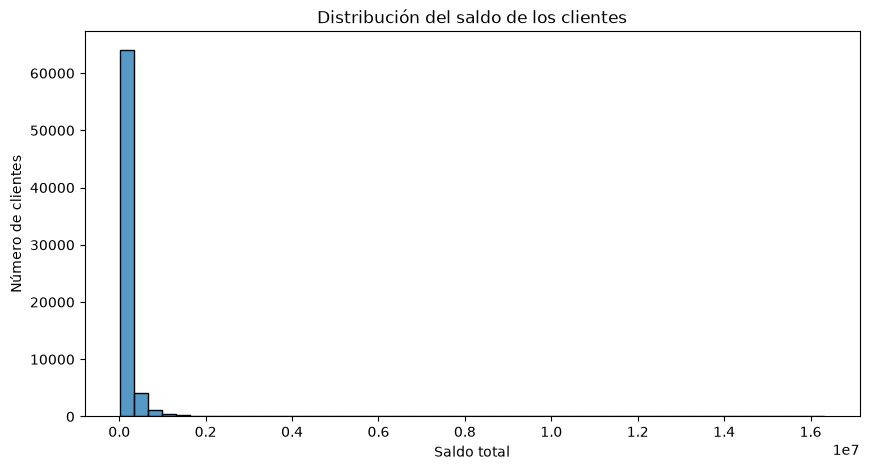

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(data=df_clientes, x='bal', bins=50)

plt.title("Distribución del saldo de los clientes")
plt.xlabel("Saldo total")
plt.ylabel("Número de clientes")
plt.show()

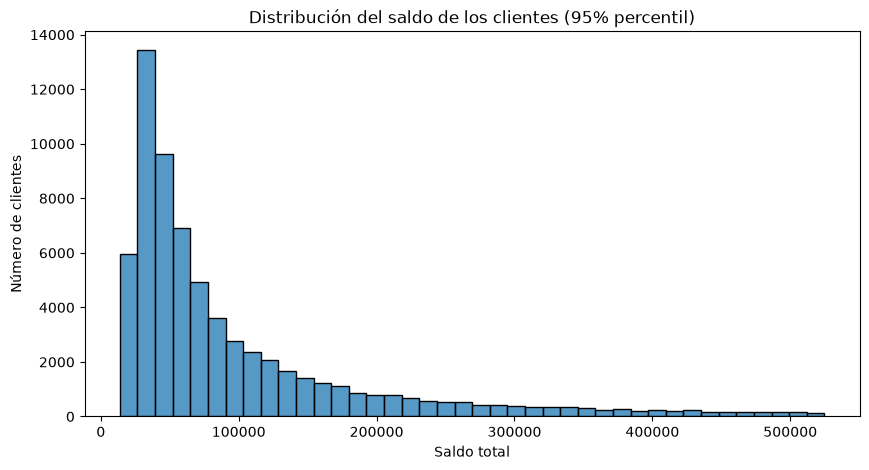

Percentil 95 del saldo: 524823.6630000005


In [18]:
limite_saldo = df_clientes['bal'].quantile(0.95)

plt.figure(figsize=(10, 5))
sns.histplot(data=df_clientes[df_clientes['bal'] <= limite_saldo], x='bal', bins=40)

plt.title("Distribución del saldo de los clientes (95% percentil)")
plt.xlabel("Saldo total")
plt.ylabel("Número de clientes")
plt.show()

print("Percentil 95 del saldo:", limite_saldo)

### Interpretación del saldo

El percentil 95 del saldo es de **524.823,66**. Aproximadamente el 95 % de los clientes con saldo disponible tiene un valor igual o inferior a esa cantidad.

Al limitar la visualización a ese intervalo, observamos que los saldos más frecuentes están por debajo de 100.000 y que la frecuencia disminuye a medida que aumenta el saldo.

La mediana de **63.332,90** describe mejor el centro de esta distribución que la media de **147.445,24**, que está influida por los saldos elevados.

El 5 % superior se ha omitido únicamente de este segundo gráfico. Todos los registros permanecen en `df_clientes`. Estas observaciones corresponden al archivo completo de perfiles, no exclusivamente a Test y Control.

## 11. Selección de clientes y comparación de los grupos

Tras revisarlo con mi compañero, analizaremos los clientes con asignación Test o Control. Los 20.109 clientes sin grupo informado quedan fuera de esta comparación, pero se conservan en la tabla original.

Compararemos los porcentajes de género y de intervalos de edad dentro de cada grupo.

Los casos cuya antigüedad supera su edad se mantienen por ahora. En el análisis de edad comprobaremos si las conclusiones cambian al excluirlos, sin modificar sus valores.

In [19]:
df_experimento = df_clientes.loc[df_clientes['Variation'].isin(['Test', 'Control'])].copy()

print("Clientes con grupo asignado:", len(df_experimento))

Clientes con grupo asignado: 50500


In [20]:
porcentaje_genero = pd.crosstab(df_experimento['Variation'],df_experimento['gendr'].fillna('Sin dato'),normalize='index') * 100

porcentaje_genero.round(2)

gendr,F,M,Sin dato,U,X
Variation,,,,,
Control,32.05,33.87,0.02,34.06,0.00
Test,32.32,33.29,0.03,34.36,0.01


### Comparación de género entre Test y Control

Los porcentajes de los códigos de género son similares en ambos grupos:

- `F`: 32,05 % en Control y 32,32 % en Test.
- `M`: 33,87 % en Control y 33,29 % en Test.
- `U`: 34,06 % en Control y 34,36 % en Test.

Los valores nulos y el código `X` representan porcentajes muy pequeños. Un porcentaje mostrado como 0,00 % puede deberse al redondeo y no implica necesariamente que no haya registros.

No observamos grandes diferencias en la composición por género. Esta comparación es descriptiva y no demuestra por sí sola que la asignación de los grupos fuera aleatoria.

Conservamos los códigos originales porque su significado no está detallado en el diccionario facilitado.

In [21]:
# Crear los mismos intervalos para ambos grupos
limites = [0, 18, 30, 40, 50, 60, 70, float('inf')]
etiquetas = [
    'Menores de 18',
    '18 a menos de 30',
    '30 a menos de 40',
    '40 a menos de 50',
    '50 a menos de 60',
    '60 a menos de 70',
    '70 o más'
]

df_experimento['grupo_edad'] = pd.cut(
    df_experimento['clnt_age'],
    bins=limites,
    labels=etiquetas,
    right=False
)

# Incluir las edades ausentes como una categoría
df_experimento['grupo_edad'] = (
    df_experimento['grupo_edad']
    .cat.add_categories('Sin dato')
    .fillna('Sin dato')
)

# Porcentajes dentro de cada grupo
porcentaje_edad = pd.crosstab(
    df_experimento['Variation'],
    df_experimento['grupo_edad'],
    normalize='index'
) * 100

porcentaje_edad.round(2)

grupo_edad,Menores de 18,18 a menos de 30,30 a menos de 40,40 a menos de 50,50 a menos de 60,60 a menos de 70,70 o más,Sin dato
Variation,,,,,,,,
Control,0.12,16.60,18.77,17.11,22.13,18.29,6.95,0.03
Test,0.13,16.92,19.49,17.21,21.69,17.88,6.66,0.03


### Resultado de la comparación por edad

El intervalo más frecuente es el de 50 a menos de 60 años: representa el 22,13 % de Control y el 21,69 % de Test.

Las distribuciones son similares. Ningún intervalo presenta una diferencia superior a un punto porcentual entre grupos.

Esta primera comparación incluye las edades registradas, también en los casos cuya antigüedad supera su edad. A continuación compruebo si excluir estos casos cambia las conclusiones.

In [22]:
# Identificar los casos cuya antigüedad supera la edad
casos_dudosos = (df_experimento['clnt_tenure_mnth'] >df_experimento['clnt_age'] * 12)

print("Casos dudosos por grupo:")
print(df_experimento.loc[casos_dudosos, 'Variation'].value_counts())

# Recalcular los porcentajes excluyendo únicamente esos casos
porcentaje_edad_sin_dudosos = pd.crosstab(
    df_experimento.loc[~casos_dudosos, 'Variation'],
    df_experimento.loc[~casos_dudosos, 'grupo_edad'],
    normalize='index'
) * 100

porcentaje_edad_sin_dudosos.round(2)

Casos dudosos por grupo:
Variation
Test       208
Control    163
Name: count, dtype: int64


grupo_edad,Menores de 18,18 a menos de 30,30 a menos de 40,40 a menos de 50,50 a menos de 60,60 a menos de 70,70 o más,Sin dato
Variation,,,,,,,,
Control,0.10,16.08,18.87,17.22,22.29,18.42,7.00,0.03
Test,0.11,16.37,19.60,17.31,21.86,18.02,6.71,0.03


### Comprobación del efecto de los casos dudosos

De los 634 casos detectados en el archivo completo, 371 tienen grupo asignado: 208 en Test y 163 en Control.

Al repetir la comparación sin estos casos:

- El intervalo más frecuente sigue siendo de 50 a menos de 60 años.
- Las diferencias entre Test y Control siguen siendo inferiores a un punto porcentual en todos los intervalos.
- El porcentaje de clientes de 18 a menos de 30 años baja ligeramente en ambos grupos.

Por tanto, excluir estos registros no cambia la conclusión descriptiva: ambos grupos presentan una composición por edad similar.

Conservamos los registros originales. Esta comprobación no confirma que las edades sean correctas, sino que los casos identificados no alteran la conclusión general de esta comparación.

## 12. Antigüedad de los clientes en Vanguard

Comparo la antigüedad de los clientes de Test y Control para conocer cuánto tiempo llevan en la empresa.

Utilizo la antigüedad expresada en años. Primero analizo los valores registrados y después comprobaré el efecto de los casos cuya antigüedad supera la edad.

In [23]:
resumen_antiguedad = (
    df_experimento.groupby('Variation')['clnt_tenure_yr']
    .agg(['count', 'mean', 'median', 'min', 'max'])
)

resumen_antiguedad.round(2)

,count,mean,median,min,max
Variation,,,,,
Control,23527,12.09,11.0,2.0,55.0
Test,26961,11.98,11.0,2.0,55.0


### Resultado de la comparación de antigüedad

Ambos grupos presentan una mediana de 11 años de antigüedad. Las medias también son similares: 12,09 años en Control y 11,98 en Test.

Estos valores indican que el cliente típico de ambos grupos mantiene una relación de varios años con Vanguard.

Hay información de antigüedad para 23.527 clientes de Control y 26.961 de Test. Quedan fuera de estos cálculos 5 y 7 clientes, respectivamente, por tener el dato ausente.

In [24]:
resumen_antiguedad_sin_dudosos = (
    df_experimento.loc[~casos_dudosos]
    .groupby('Variation')['clnt_tenure_yr']
    .agg(['count', 'mean', 'median', 'min', 'max'])
)

resumen_antiguedad_sin_dudosos.round(2)

,count,mean,median,min,max
Variation,,,,,
Control,23364,11.99,11.0,2.0,55.0
Test,26753,11.87,11.0,2.0,55.0


### Antigüedad al excluir los casos dudosos

Al excluir los clientes cuya antigüedad supera su edad:

- La media de Control pasa de 12,09 a 11,99 años.
- La media de Test pasa de 11,98 a 11,87 años.
- La mediana permanece en 11 años en ambos grupos.

La exclusión apenas modifica el resumen y no cambia la conclusión: Test y Control presentan una antigüedad similar.

Los registros se conservan en la tabla principal del experimento. Esta exclusión se ha utilizado únicamente como comprobación de sensibilidad del análisis de antigüedad.

## 13. Saldo y actividad previa por grupo

Comparo el saldo, el número de cuentas, las llamadas y los accesos de los últimos seis meses entre Test y Control.

Utilizo la media y la mediana para resumir cada variable. En el saldo prestaré especial atención a la mediana, porque los valores elevados influyen en la media.

Mantengo todos los clientes con grupo asignado. Los valores ausentes se excluyen únicamente del cálculo de la variable correspondiente.

In [25]:
columnas = ['bal', 'num_accts', 'calls_6_mnth', 'logons_6_mnth']

resumen_perfil = (
    df_experimento.groupby('Variation')[columnas]
    .agg(['mean', 'median'])
)

resumen_perfil.round(2)

bal           num_accts        calls_6_mnth         \
                mean    median      mean median         mean median   
Variation                                                             
Control    150147.33  66024.18      2.26    2.0         3.13    3.0   
Test       148962.61  65468.36      2.25    2.0         3.06    3.0   

          logons_6_mnth         
                   mean median  
Variation                       
Control            6.17    6.0  
Test               6.10    6.0

### Resultado de la comparación de saldo y actividad previa

Test y Control presentan medias y medianas similares en las variables revisadas.

El saldo mediano es de 66.024,18 en Control y 65.468,36 en Test, una diferencia de aproximadamente 556. En ambos grupos, la media del saldo supera ampliamente a la mediana, reflejando la influencia de los saldos elevados.

Las medianas coinciden en número de cuentas (2), llamadas (3) y accesos (6). Las medias de estas variables también son cercanas.

Junto con las comparaciones de edad, género y antigüedad, estos resultados no muestran grandes desequilibrios en los resúmenes del perfil. Sin embargo, no demuestran que los grupos sean idénticos ni que la asignación haya sido aleatoria.

## 14. Comparación visual de los perfiles

Represento los porcentajes por intervalo de edad dentro de Test y Control. Utilizo porcentajes porque los grupos tienen distinto número de clientes.

El gráfico incluye todos los clientes con grupo asignado. La comprobación anterior mostró que excluir los casos cuya antigüedad supera su edad no cambia la conclusión general.

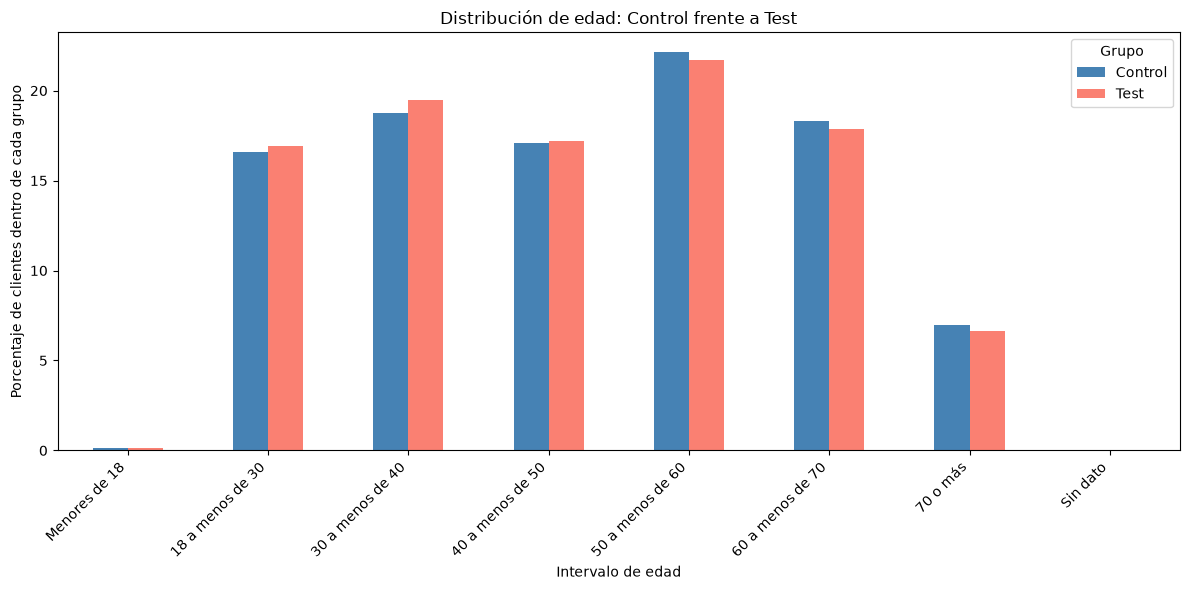

In [26]:
porcentaje_edad.T.plot(
    kind='bar',
    figsize=(12, 6),
    color=['steelblue', 'salmon']
)

plt.title("Distribución de edad: Control frente a Test")
plt.xlabel("Intervalo de edad")
plt.ylabel("Porcentaje de clientes dentro de cada grupo")
plt.xticks(rotation=45, ha='right')
plt.legend(title="Grupo")
plt.tight_layout()
plt.show()

El gráfico confirma visualmente la similitud de la distribución de edad entre Test y Control. El intervalo con mayor presencia es de 50 a menos de 60 años, con aproximadamente un 22 % en ambos grupos.

No se observan grandes diferencias por intervalo, aunque esto no demuestra por sí solo que la asignación fuera aleatoria.

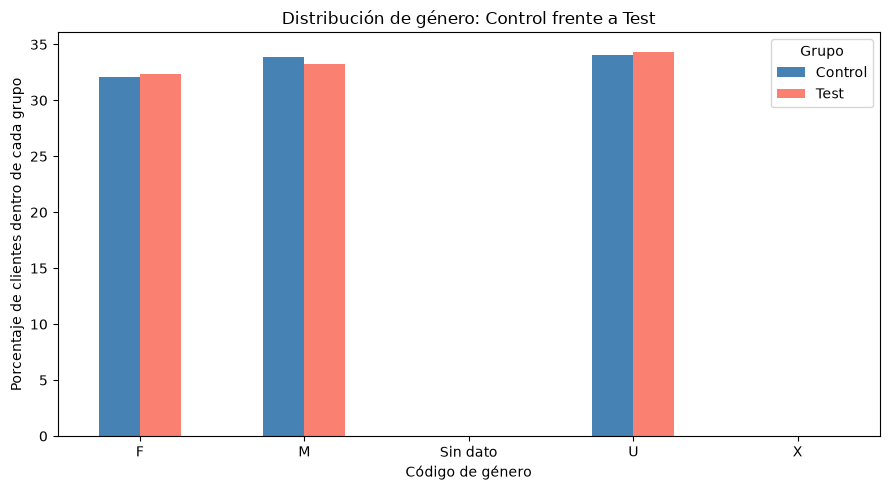

In [27]:
porcentaje_genero.T.plot(
    kind='bar',
    figsize=(9, 5),
    color=['steelblue', 'salmon']
)

plt.title("Distribución de género: Control frente a Test")
plt.xlabel("Código de género")
plt.ylabel("Porcentaje de clientes dentro de cada grupo")
plt.xticks(rotation=0)
plt.legend(title="Grupo")
plt.tight_layout()
plt.show()

La distribución de los códigos de género es similar en Test y Control. `F`, `M` y `U` representan cada uno aproximadamente un tercio de cada grupo.

La mayor diferencia es de 0,58 puntos porcentuales en `M`, con mayor presencia en Control. Los códigos originales se mantienen sin reinterpretarlos.

## 15. Resumen y conclusiones de la exploración de clientes

### Datos revisados y preparación

He revisado los archivos de perfiles y asignación al experimento. Ambos contienen los mismos **70.609 clientes únicos**, sin identificadores duplicados.

Los he unido mediante `client_id`, conservando una fila por cliente.

Para comparar las interfaces, hemos acordado utilizar los **50.500 clientes con grupo asignado**:

- **Test:** 26.968 clientes.
- **Control:** 23.532 clientes.

Los **20.109 clientes sin asignación informada** quedan fuera de esta comparación, pero se conservan en la tabla original.

### Calidad de los datos

He identificado estas incidencias:

- 14 clientes tienen únicamente el identificador, sin información de perfil.
- Un cliente adicional no tiene edad registrada.
- La columna de género contiene los códigos `F`, `M`, `U` y `X`, además de nulos. Mantengo los códigos originales porque el diccionario no especifica su significado.
- Hay 634 clientes cuya antigüedad supera su edad; 371 pertenecen a Test o Control.

No he corregido ni eliminado automáticamente estos registros. Al repetir las comparaciones de edad y antigüedad sin los casos dudosos, las conclusiones generales se mantienen.

### Perfil de los clientes con grupo asignado

Los participantes abarcan distintas edades. El intervalo más frecuente es **de 50 a menos de 60 años**, que representa aproximadamente el 22 % de cada grupo. Es el intervalo más numeroso, pero no constituye una mayoría.

La mediana de antigüedad es de **11 años en ambos grupos**, por lo que el perfil central corresponde a clientes con una relación de varios años con Vanguard.

Las medianas también coinciden en:

- **2 cuentas** por cliente.
- **3 llamadas** en los últimos seis meses.
- **6 accesos** a la plataforma en los últimos seis meses.

El saldo mediano ronda los **65.000–66.000**. La media es bastante mayor, debido a la influencia de los saldos elevados.

### Comparación entre Test y Control

No se observan grandes diferencias en los aspectos revisados:

- Las diferencias por intervalo de edad son inferiores a un punto porcentual.
- La mayor diferencia entre códigos de género es de 0,58 puntos porcentuales.
- La antigüedad media es de 12,09 años en Control y 11,98 en Test, con una mediana de 11 años en ambos.
- El saldo mediano es de 66.024,18 en Control y 65.468,36 en Test.
- El número de cuentas y la actividad previa presentan medias y medianas similares.

Estas similitudes son una primera señal favorable para comparar los grupos. Sin embargo, no demuestran que sean equivalentes en todas sus características ni que la asignación haya sido aleatoria.

### Alcance de las conclusiones

Esta fase describe a los clientes con grupo asignado. Todavía falta comprobar cuáles tienen actividad web registrada, por lo que aún no podemos afirmar que todos hayan utilizado el proceso.

Tampoco podemos concluir si la nueva interfaz funciona mejor: para ello necesitamos analizar los recorridos y comparar las métricas de rendimiento.

### Próximos pasos con mi compañero

1. Relacionar los clientes asignados con los eventos web preparados por mi compañero.
2. Comprobar cuántos clientes de Test y Control tienen actividad registrada.
3. Acordar el tratamiento de los clientes sin eventos, sin considerarlos abandonos automáticamente.
4. Definir las métricas del día 3, indicando si se calculan por cliente o por sesión.
5. Comparar el rendimiento de ambas interfaces y, posteriormente, realizar los contrastes de hipótesis.

## 16. Exploración y preparación de la actividad web

Los eventos del proceso están repartidos en dos archivos con las mismas columnas. Primero los cargaré y uniré sus filas.

Después revisaré los valores ausentes, los duplicados, las fechas y los pasos registrados antes de reconstruir los recorridos.

In [28]:
df_web_1 = pd.read_csv("data/df_final_web_data_pt_1.txt")
df_web_2 = pd.read_csv("data/df_final_web_data_pt_2.txt")

df_web = pd.concat([df_web_1, df_web_2], ignore_index=True)

print("Filas de la primera parte:", len(df_web_1))
print("Filas de la segunda parte:", len(df_web_2))
print("Filas después de unir:", len(df_web))
print("Coincide la suma:", len(df_web) == len(df_web_1) + len(df_web_2))

df_web.info()

Filas de la primera parte: 343141
Filas de la segunda parte: 412264
Filas después de unir: 755405
Coincide la suma: True
<class 'pandas.DataFrame'>
RangeIndex: 755405 entries, 0 to 755404
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   client_id     755405 non-null  int64
 1   visitor_id    755405 non-null  str  
 2   visit_id      755405 non-null  str  
 3   process_step  755405 non-null  str  
 4   date_time     755405 non-null  str  
dtypes: int64(1), str(4)
memory usage: 81.6 MB


### Resultado de la carga y unión

La primera parte contiene 343.141 filas y la segunda, 412.264. Al concatenarlas obtenemos 755.405 eventos, coincidiendo con la suma de ambos archivos.

No hay valores nulos en las cinco columnas. La columna `date_time` está almacenada como texto y deberá convertirse a fecha y hora.

Cada fila representa un evento registrado. Que un cliente o una sesión aparezcan varias veces no implica que sean duplicados.

In [29]:
print("Filas exactamente duplicadas:", df_web.duplicated().sum())

print("\nEventos por paso:")
print(df_web['process_step'].value_counts(dropna=False))

Filas exactamente duplicadas: 10764

Eventos por paso:
process_step
start      243945
step_1     163193
step_2     133062
step_3     112242
confirm    102963
Name: count, dtype: int64


## 17. Duplicados y pasos del proceso

Se han detectado 10.764 filas exactamente duplicadas. Para evitar contar varias veces el mismo registro, conservaré una sola copia de cada combinación de las cinco columnas.

Esta decisión no elimina las visitas repetidas de un cliente ni los eventos del mismo paso con distinta fecha y hora.

Los pasos registrados son los esperados: start, step_1, step_2, step_3 y confirm. Sus frecuencias representan eventos, no clientes únicos.

In [30]:
df_web_limpio = df_web.drop_duplicates().copy()

print("Eventos conservados:", len(df_web_limpio))
print("Duplicados restantes:", df_web_limpio.duplicated().sum())

Eventos conservados: 744641
Duplicados restantes: 0


## 18. Revisión de fechas de la actividad web

Convierto `date_time` de texto a fecha y hora para poder ordenar los eventos y calcular duraciones.

Compruebo si hay fechas que no se pueden interpretar y cuál es el intervalo temporal registrado. El periodo indicado para el experimento es del 15 de marzo al 20 de junio de 2017.

In [ ]:
df_web_limpio['date_time'] = pd.to_datetime(df_web_limpio['date_time'],errors='coerce')

print("Fechas no válidas:", df_web_limpio['date_time'].isna().sum())
print("Primera fecha:", df_web_limpio['date_time'].min())
print("Última fecha:", df_web_limpio['date_time'].max())

Fechas no válidas: 0
Primera fecha: 2017-03-15 00:03:03
Última fecha: 2017-06-20 23:59:57


### Resultado de la revisión de fechas

Todos los eventos tienen una fecha válida. El primer registro es del 15 de marzo de 2017 y el último, del 20 de junio de 2017.

El intervalo coincide con el periodo indicado para el experimento. No es necesario excluir eventos por estar fuera de esas fechas.

In [32]:
clientes_por_visita = (df_web_limpio.groupby('visit_id')['client_id'].nunique())

print("Visitas únicas:", len(clientes_por_visita))
print("Visitas asociadas a varios clientes:",
      (clientes_por_visita > 1).sum())

Visitas únicas: 158095
Visitas asociadas a varios clientes: 1012


## 19. Revisión de las sesiones

Hay 158.095 identificadores de visita distintos. De ellos, 1.012 aparecen asociados a más de un cliente.

Para evitar mezclar sus eventos, utilizaré la combinación de `client_id` y `visit_id` al reconstruir los recorridos y calcular tiempos y retrocesos.

No elimino estos registros: esta comprobación no permite determinar por qué comparten el identificador de visita.

In [33]:
pasos_por_instante = (df_web_limpio.groupby(['client_id', 'visit_id', 'date_time'])['process_step'].nunique())

print("Instantes con varios pasos distintos:",(pasos_por_instante > 1).sum())

Instantes con varios pasos distintos: 943


### Eventos con la misma fecha y hora

Se han identificado 943 combinaciones de cliente, visita y fecha con más de un paso distinto.

Estos eventos se conservan. Sin embargo, su orden es ambiguo y deberá tenerse en cuenta al calcular tiempos y retrocesos: no se ordenarán artificialmente por el nombre del paso.

In [34]:
clientes_con_web = df_web_limpio['client_id'].unique()

df_experimento['tiene_actividad_web'] = (df_experimento['client_id'].isin(clientes_con_web))

pd.crosstab(df_experimento['Variation'],df_experimento['tiene_actividad_web'])

tiene_actividad_web,True
Variation,
Control,23532
Test,26968


## 20. Comprobación de actividad de los participantes

Todos los clientes con grupo asignado aparecen en los datos web:

- Control: 23.532 clientes.
- Test: 26.968 clientes.

Por tanto, la población con asignación conocida coincide con la población asignada que tiene actividad registrada.

Tener algún evento no implica haber iniciado en `start` ni haber completado el proceso.

In [35]:
df_web_experimento = df_web_limpio.merge(df_experimento[['client_id', 'Variation']],on='client_id',how='inner',validate='many_to_one')

print("Eventos de participantes:", len(df_web_experimento))
print("Clientes únicos:", df_web_experimento['client_id'].nunique())

print("\nClientes por grupo:")
print(df_web_experimento.groupby('Variation')['client_id'].nunique())

Eventos de participantes: 317235
Clientes únicos: 50500

Clientes por grupo:
Variation
Control    23532
Test       26968
Name: client_id, dtype: int64


In [36]:
# Total de clientes únicos por grupo
clientes_por_grupo = (df_web_experimento.groupby('Variation')['client_id'].nunique())

# Clientes que tienen al menos una confirmación
clientes_completan = (df_web_experimento.loc[df_web_experimento['process_step'] == 'confirm'].groupby('Variation')['client_id'].nunique())

# Reunir los recuentos y calcular el porcentaje
resumen_finalizacion = pd.DataFrame({'clientes': clientes_por_grupo,'completan': clientes_completan}).fillna(0)

resumen_finalizacion['tasa_finalizacion'] = (resumen_finalizacion['completan'] /resumen_finalizacion['clientes'] * 100)

resumen_finalizacion.round(2)

,clientes,completan,tasa_finalizacion
Variation,,,
Control,23532,15434,65.59
Test,26968,18687,69.29


### Resultado de la tasa de finalización

El 69,29 % de los clientes de Test alcanza la confirmación, frente al 65,59 % de Control.

La diferencia es de aproximadamente 3,70 puntos porcentuales, equivalente a una mejora relativa del 5,64 % respecto a Control.

Este resultado descriptivo favorece a la nueva interfaz. Todavía debemos comprobar su significación estadística y aclarar si el umbral del 5 % solicitado se refiere a mejora relativa o a puntos porcentuales.

## 22. Tiempo transcurrido en cada paso

Estimaré el tiempo de cada paso como la diferencia entre su fecha y la del siguiente evento del mismo cliente y visita.

El último evento de una visita no tiene duración observable. Tampoco interpretaré el tiempo posterior a `confirm` como tiempo necesario para completar.

Antes del cálculo, identificaré los instantes con pasos distintos registrados a la misma hora, porque no podemos determinar su orden.

In [37]:
# Ordenar los eventos dentro de cada recorrido
df_web_experimento = df_web_experimento.sort_values(['client_id', 'visit_id', 'date_time']).copy()

# Identificar instantes con más de un paso distinto
pasos_misma_hora = (df_web_experimento.groupby(['client_id', 'visit_id', 'date_time'])['process_step'].transform('nunique'))

df_web_experimento['orden_ambiguo'] = pasos_misma_hora > 1

print("Eventos en instantes con orden ambiguo:",df_web_experimento['orden_ambiguo'].sum())

Eventos en instantes con orden ambiguo: 1052


In [38]:
# Siguiente evento del mismo cliente y visita
sesiones = df_web_experimento.groupby(['client_id', 'visit_id'])

df_web_experimento['fecha_siguiente'] = (sesiones['date_time'].shift(-1))

df_web_experimento['siguiente_ambiguo'] = (sesiones['orden_ambiguo'].shift(-1))

# Duración en segundos
df_web_experimento['duracion_segundos'] = (df_web_experimento['fecha_siguiente'] -df_web_experimento['date_time']).dt.total_seconds()

# Seleccionar intervalos que podemos interpretar
intervalos_validos = ((~df_web_experimento['orden_ambiguo']) &(df_web_experimento['siguiente_ambiguo'] == False) &(df_web_experimento['duracion_segundos'] > 0) &(df_web_experimento['process_step'] != 'confirm')
)

df_tiempos = df_web_experimento.loc[intervalos_validos].copy()

resumen_tiempos = (df_tiempos.groupby(['Variation', 'process_step'])['duracion_segundos'].agg(['count', 'mean', 'median', 'max']).round(2))

resumen_tiempos

count    mean  median      max
Variation process_step                                
Control   start         35730   66.84    20.0  40235.0
          step_1        26016   50.52    20.0  10286.0
          step_2        24175   92.23    64.0  21763.0
          step_3        19814  138.03    73.0   6164.0
Test      start         46296   61.49    14.0  24819.0
          step_1        35437   60.77    27.0   8797.0
          step_2        29406   89.23    61.0  11204.0
          step_3        23780  129.98    58.0   6692.0

### Primera comparación de tiempos por paso

Test presenta tiempos medios y medianos menores en el inicio y en los pasos 2 y 3. Sin embargo, en el paso 1 los tiempos son mayores: la mediana pasa de 20 segundos en Control a 27 en Test.

El paso 3 tiene el mayor tiempo medio en ambos grupos. Su mediana baja de 73 a 58 segundos con la nueva interfaz.

Se observan intervalos de varias horas que pueden incluir pausas. Por eso, las medias se interpretan junto con las medianas. No se han eliminado automáticamente los intervalos largos.

Estos resultados describen intervalos observables entre eventos, incluyendo repeticiones y retrocesos. No representan necesariamente el tiempo de avance correcto ni permiten concluir que una menor duración sea siempre una mejora.

In [40]:
porcentaje_pausas = (df_tiempos.assign(supera_30_min=df_tiempos['duracion_segundos'] > 1800).groupby(['Variation', 'process_step'])['supera_30_min'].mean() * 100)

porcentaje_pausas.round(2)

Variation  process_step
Control    start           0.18
           step_1          0.10
           step_2          0.05
           step_3          0.14
Test       start           0.19
           step_1          0.08
           step_2          0.02
           step_3          0.19
Name: supera_30_min, dtype: float64

### Comprobación de sensibilidad a las pausas largas

Los intervalos superiores a 30 minutos representan entre el 0,02 % y el 0,19 % de los intervalos válidos por paso y grupo.

Repito el resumen excluyéndolos únicamente para comprobar su influencia. El umbral de 30 minutos es una referencia exploratoria, no una regla establecida por Vanguard ni una prueba de que esos registros sean errores.

Los datos y el cálculo principal se conservan.

In [41]:
resumen_tiempos_sin_pausas = (df_tiempos.loc[df_tiempos['duracion_segundos'] <= 1800].groupby(['Variation', 'process_step'])['duracion_segundos'].agg(['count', 'mean', 'median']).round(2))

resumen_tiempos_sin_pausas

count    mean  median
Variation process_step                       
Control   start         35665   60.89    20.0
          step_1        25990   47.51    20.0
          step_2        24164   90.39    64.0
          step_3        19786  134.19    73.0
Test      start         46210   56.27    14.0
          step_1        35409   58.58    27.0
          step_2        29401   88.48    61.0
          step_3        23734  125.13    58.0

### Conclusión sobre los tiempos por paso

Al excluir los intervalos superiores a 30 minutos, las medias disminuyen, pero se mantiene el patrón observado:

- Test registra tiempos menores en `start`, `step_2` y `step_3`.
- En `step_1`, Test registra tiempos mayores que Control.
- Las medianas no cambian en ningún paso ni grupo.

Por tanto, las pausas largas no explican la dirección de las diferencias. Conservamos como resultado principal el cálculo con todos los intervalos válidos y utilizamos esta comparación como comprobación adicional.

La nueva interfaz no reduce los tiempos en todos los pasos. El paso 1 merece atención al analizar los retrocesos y la finalización.

## 23. Tasa de retrocesos

Según el enunciado, consideramos error una transición hacia un paso anterior dentro del mismo cliente y visita.

Calculamos:

Número de retrocesos / número de transiciones evaluables × 100.

Excluimos las transiciones cuyo origen o destino tiene un orden ambiguo y los eventos sin siguiente paso. Las repeticiones del mismo paso cuentan en el denominador, pero no como errores.

Esta métrica describe retrocesos registrados; no demuestra por sí sola que exista un fallo técnico.

In [42]:
# Asignar un orden a los pasos
orden_pasos = {'start': 0,'step_1': 1,'step_2': 2,'step_3': 3,'confirm': 4}

df_web_experimento['orden_paso'] = (df_web_experimento['process_step'].map(orden_pasos))

# Obtener el siguiente paso dentro del mismo cliente y visita
df_web_experimento['orden_siguiente'] = (df_web_experimento.groupby(['client_id', 'visit_id'])['orden_paso'].shift(-1))

# Seleccionar transiciones cuyo orden podemos interpretar
transiciones_validas = ((~df_web_experimento['orden_ambiguo']) &(df_web_experimento['siguiente_ambiguo'] == False) &(df_web_experimento['orden_siguiente'].notna()) &(df_web_experimento['duracion_segundos'] > 0))

df_transiciones = df_web_experimento.loc[transiciones_validas].copy()

df_transiciones['retroceso'] = (df_transiciones['orden_siguiente'] < df_transiciones['orden_paso'])

resumen_errores = (df_transiciones.groupby('Variation')['retroceso'].agg(['count', 'sum', 'mean']).rename(columns={'count': 'transiciones_evaluables','sum': 'retrocesos','mean': 'tasa_retrocesos'}))

resumen_errores['tasa_retrocesos'] *= 100

resumen_errores.round(2)

,transiciones_evaluables,retrocesos,tasa_retrocesos
Variation,,,
Control,107550,9318,8.66
Test,138990,15980,11.50


### Resultado de la tasa de retrocesos

En Control se registran 9.318 retrocesos entre 107.550 transiciones evaluables (8,66 %). En Test aparecen 15.980 entre 138.990 transiciones (11,50 %).

La nueva interfaz presenta una tasa de retrocesos aproximadamente 2,84 puntos porcentuales superior. Este porcentaje se refiere a transiciones, no a clientes: una persona puede retroceder varias veces.

El resultado contrasta con la mayor tasa de finalización de Test. La nueva interfaz consigue que más clientes lleguen a confirmar, pero sus recorridos también presentan más movimientos hacia pasos anteriores.

Los retrocesos pueden señalar dificultades, aunque no demuestran errores técnicos. Además, el cálculo incluye movimientos posteriores a `confirm`, que podrían corresponder a nuevas acciones dentro de la misma visita.

Estos resultados son descriptivos y todavía no hemos contrastado estadísticamente sus diferencias.